# Train Card Strength Model

**Objectives:**
- Prepare the dataset for training by splitting and scaling features.
- Train an late fusion model.
- Evaluate model accuracy using MAE and RMSE metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

from embeddings.mtg_dataset import MTGDataset
from embeddings.mtg_fusion_model import MTGFusionModel

In [2]:
INPUT_DATA_PATH = "../data/training/card_strength_input.parquet"
LABEL_DATA_PATH = "../data/training/card_strength_metric.xlsx"
OUTPUT_MODEL_PATH = "../models/card_strength_model.pth"
SEED = 1893
EPOCHS = 50
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [24]:
np.random.seed(SEED)
df_input = pd.read_parquet(INPUT_DATA_PATH)
df_label = pd.read_excel(LABEL_DATA_PATH)

cols_to_use = df_label.columns.difference(df_input.columns).tolist()
df = df_input.merge(df_label[cols_to_use + ["oracle_id"]], on="oracle_id", how="left")

# TODO (for me): investigate how log_power_score of nan is possible earlier in the workflow
print(f"Shape: {df.shape}")
# Remove rows with missing targets or infinite values
df = df.dropna(subset=["log_power_score"])
df = df[np.isfinite(df["log_power_score"])]

print(f"Shape: {df.shape}")
df.head()[df.columns[:8]]

Shape: (29677, 805)
Shape: (29616, 805)


,oracle_id,name,card_faces,mana_cost,cmc,type_line,oracle_text,power
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",None,{3}{G},4.0,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3
1,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,None,{3},3.0,Artifact,"As long as this artifact is untapped, players ...",None
2,0006faf6-7a61-426c-9034-579f2cfcfa83,Sensory Deprivation,None,{U},1.0,Enchantment — Aura,Enchant creature\nEnchanted creature gets -3/-0.,None
3,0007c283-5b7a-4c00-9ca1-b455c8dff8c3,Road of Return,None,{G}{G},2.0,Sorcery,Choose one —\n• Return target permanent card f...,None
4,000d5588-5a4c-434e-988d-396632ade42c,Storm Crow,None,{1}{U},2.0,Creature — Bird,Flying (This creature can't be blocked except ...,1


## Data Filtering

Exclude most recent set (and every card that has been release since to avoid inaccuracies)

In [4]:
# TODO (for later): from all sets find the most recent (that has been released)
# -> filter all cards from that set and cards that are released after that (like secret lairs)

## Feature Preparation

In [ ]:
embedding_cols = [col for col in df.columns if col.startswith('embed_')]
numerical_cols = [col for col in df.columns if col.startswith('num_')]
boolean_cols = [col for col in df.columns if col.startswith('bool_')]
embedding_features = df[embedding_cols].values
numerical_features = df[numerical_cols].values
boolean_features = df[boolean_cols].values

feature_cols = embedding_cols + numerical_cols + boolean_cols
target_col = 'log_power_score'

print(f"Number of embedding dimensions: {len(embedding_cols)}")
print(f"Number of numerical features: {len(numerical_cols)}")
print(f"  -> {", ".join(numerical_cols)}")
print(f"Number of boolean features: {len(boolean_cols)}")
print(f"  -> {", ".join(boolean_cols)}")

Number of embedding dimensions: 768
Number of numerical features: 5
  -> num_cmc, num_power, num_toughness, num_loyalty, num_colors
Number of boolean features: 11
  -> bool_is_game_changer, bool_power_var, bool_toughness_var, bool_is_planeswalker, bool_has_x_cost, bool_is_legendary, bool_is_colorless, bool_is_modal, bool_is_transform, bool_is_saga, bool_is_class


## Correlation Analysis

- Calculate Pearson correlation between features and the target power score.
- Plot the top positive and negative correlations to validate feature engineering.

In [ ]:
correlations = df[feature_cols + [target_col]].corr()[target_col].drop(target_col)
top_correlations = pd.concat([correlations.nsmallest(10), correlations.nlargest(10)]).sort_values()

plt.figure(figsize=(12, 8))
sns.barplot(x=top_correlations.values, y=top_correlations.index)
plt.title('Top Correlations with Power Score', fontsize=16)
plt.show()

## Data Splitting

- Split data into Training (60%), Validation (20%), and Test (20%) sets.
- Ensure stratification and reproducibility using the defined seed.

In [7]:
text_embeddings = df[embedding_cols].values
tabular_features = df[numerical_cols + boolean_cols].fillna(-1).values

# TODO: maybe have to scale embedding features?
tabular_features = df[numerical_cols + boolean_cols].fillna(-1).values
scaler = StandardScaler()
tabular_features = scaler.fit_transform(tabular_features)

targets = df[target_col].values

X_text_train_val, X_text_test, X_tab_train_val, X_tab_test, y_train_val, y_test = train_test_split(
    text_embeddings, tabular_features, targets, test_size=0.20, random_state=SEED
)

X_text_train, X_text_val, X_tab_train, X_tab_val, y_train, y_val = train_test_split(
    X_text_train_val, X_tab_train_val, y_train_val, test_size=0.25, random_state=SEED
)

train_ds = MTGDataset(X_text_train, X_tab_train, y_train)
val_ds = MTGDataset(X_text_val, X_tab_val, y_val)
test_ds = MTGDataset(X_text_test, X_tab_test, y_test)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)

print(f"Training data: {X_text_train.shape[0]} cards")
print(f"Validation data: {X_text_val.shape[0]} cards")
print(f"Test data: {X_text_test.shape[0]} cards")

Training data: 17769 cards
Validation data: 5923 cards
Test data: 5924 cards


## Create baselines

### Full XGBoost baseline

In [8]:
X_train_xgb = np.hstack([X_text_train, X_tab_train])
X_val_xgb = np.hstack([X_text_val, X_tab_val])
X_test_xgb = np.hstack([X_text_test, X_tab_test])

xgb_reg = XGBRegressor(
    random_state=SEED, 
    device=DEVICE
)

xgb_reg.fit(
    X=X_train_xgb,
    y=y_train, 
    eval_set=[(X_val_xgb, y_val)], 
    verbose=10
)

y_pred_xgb = xgb_reg.predict(X_test_xgb)
print(f"\nFull XGBoost Baseline Metrics:")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_xgb):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_xgb)):.4f}")
print(f"Test R2: {r2_score(y_test, y_pred_xgb):.4f}")

[0]	validation_0-rmse:9.20679
[10]	validation_0-rmse:8.37892
[20]	validation_0-rmse:8.24610
[30]	validation_0-rmse:8.21783
[40]	validation_0-rmse:8.19886
[50]	validation_0-rmse:8.19396
[60]	validation_0-rmse:8.19034
[70]	validation_0-rmse:8.18474
[80]	validation_0-rmse:8.18612
[90]	validation_0-rmse:8.18436
[99]	validation_0-rmse:8.17948

Full XGBoost Baseline Metrics:
Test MAE: 6.4848
Test RMSE: 8.1427
Test R2: 0.3085


### Tabular-only XGBoost model

In [9]:
xgb_reg.fit(
    X=X_tab_train,
    y=y_train, 
    eval_set=[(X_tab_val, y_val)], 
    verbose=10
)

y_pred_tab_xgb = xgb_reg.predict(X_tab_test)
print(f"\nXGBoost Baseline Metrics:")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred_tab_xgb):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_tab_xgb)):.4f}")
print(f"Test R2: {r2_score(y_test, y_pred_tab_xgb):.4f}")

[0]	validation_0-rmse:9.25542
[10]	validation_0-rmse:8.69611
[20]	validation_0-rmse:8.67878
[30]	validation_0-rmse:8.67495
[40]	validation_0-rmse:8.68650
[50]	validation_0-rmse:8.68502
[60]	validation_0-rmse:8.69245
[70]	validation_0-rmse:8.69816
[80]	validation_0-rmse:8.70452
[90]	validation_0-rmse:8.70563
[99]	validation_0-rmse:8.71263

XGBoost Baseline Metrics:
Test MAE: 7.0028
Test RMSE: 8.6638
Test R2: 0.2172


### Embedding-only Linear Baseline

In [10]:
class EmbeddingLinearModel(nn.Module):
    def __init__(self, text_dim):
        super(EmbeddingLinearModel, self).__init__()
        self.linear = nn.Linear(text_dim, 1)

    def forward(self, text_embeddings, _):
        out = self.linear(text_embeddings)
        return out.squeeze(-1)

linear_model = EmbeddingLinearModel(text_dim=len(embedding_cols)).to(DEVICE)
linear_optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.001)
linear_criterion = nn.HuberLoss(delta=3.0)
best_linear_model = None

best_linear_loss = float('inf')
for epoch in range(EPOCHS):
    linear_model.train()
    train_loss = 0
    for texts, tabs, labels in train_loader:
        texts, labels = texts.to(DEVICE), labels.to(DEVICE)
        linear_optimizer.zero_grad()
        outputs = linear_model(texts, None)
        loss = linear_criterion(outputs, labels)
        loss.backward()
        linear_optimizer.step()
        train_loss += loss.item() * texts.size(0)
    train_loss /= len(train_loader.dataset)
    
    linear_model.eval()
    val_loss = 0
    with torch.no_grad():
        for texts, tabs, labels in val_loader:
            texts, labels = texts.to(DEVICE), labels.to(DEVICE)
            outputs = linear_model(texts, None)
            loss = linear_criterion(outputs, labels)
            val_loss += loss.item() * texts.size(0)
    val_loss /= len(val_loader.dataset)

    if val_loss < best_linear_loss:
        best_linear_loss = val_loss
        # TODO: save best linear baseline in memory (do i need deepcopy for that?)
        best_linear_model = linear_model

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

print(f"Embedding Linear Baseline training complete. Best Val Loss: {best_linear_loss:.4f}")

# test linear embedding model
best_linear_model.eval()

linear_preds = []
with torch.no_grad():
    for texts, tabs, labels in test_loader:
        texts = texts.to(DEVICE)
        outputs = best_linear_model(texts, None)
        linear_preds.extend(outputs.cpu().numpy())
y_pred_linear = np.array(linear_preds)

Epoch 1/50 | Train Loss: 27.2184 | Val Loss: 18.7161
Epoch 10/50 | Train Loss: 16.1902 | Val Loss: 16.1658
Epoch 20/50 | Train Loss: 15.7010 | Val Loss: 15.8026
Epoch 30/50 | Train Loss: 15.4514 | Val Loss: 15.7391
Epoch 40/50 | Train Loss: 15.2985 | Val Loss: 15.6072
Epoch 50/50 | Train Loss: 15.1768 | Val Loss: 15.4120
Embedding Linear Baseline training complete. Best Val Loss: 15.4120


## Train late fusion model

In [11]:
model = MTGFusionModel(
    text_dim=len(embedding_cols), 
    tabular_dim=X_tab_train.shape[1]
).to(DEVICE)

criterion = torch.nn.HuberLoss(delta=3.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.1)

In [12]:
best_loss = float('inf')

for epoch in range(EPOCHS):
    # train
    model.train()
    train_loss = 0
    for texts, tabs, labels in train_loader:
        texts, tabs, labels = texts.to(DEVICE), tabs.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(texts, tabs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * texts.size(0)
        
    train_loss /= len(train_loader.dataset)
    
    # validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for texts, tabs, labels in val_loader:
            texts, tabs, labels = texts.to(DEVICE), tabs.to(DEVICE), labels.to(DEVICE)
            outputs = model(texts, tabs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * texts.size(0)
    
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "best_fusion_model.pth")
        
print(f"Training complete. Best Val Loss: {best_loss:.4f}")

Epoch 1/50 | Train Loss: 60.2605 | Val Loss: 20.3660
Epoch 2/50 | Train Loss: 19.4133 | Val Loss: 18.3443
Epoch 3/50 | Train Loss: 17.9041 | Val Loss: 17.4553
Epoch 4/50 | Train Loss: 17.1646 | Val Loss: 16.9768
Epoch 5/50 | Train Loss: 16.7090 | Val Loss: 16.6608
Epoch 6/50 | Train Loss: 16.3945 | Val Loss: 16.4142
Epoch 7/50 | Train Loss: 16.1488 | Val Loss: 16.2484
Epoch 8/50 | Train Loss: 15.9616 | Val Loss: 16.1103
Epoch 9/50 | Train Loss: 15.8057 | Val Loss: 15.9819
Epoch 10/50 | Train Loss: 15.6872 | Val Loss: 15.9329
Epoch 11/50 | Train Loss: 15.5830 | Val Loss: 15.8390
Epoch 12/50 | Train Loss: 15.4956 | Val Loss: 15.7476
Epoch 13/50 | Train Loss: 15.4150 | Val Loss: 15.6796
Epoch 14/50 | Train Loss: 15.3508 | Val Loss: 15.6454
Epoch 15/50 | Train Loss: 15.3026 | Val Loss: 15.6307
Epoch 16/50 | Train Loss: 15.2441 | Val Loss: 15.5646
Epoch 17/50 | Train Loss: 15.2055 | Val Loss: 15.5123
Epoch 18/50 | Train Loss: 15.1584 | Val Loss: 15.4819
Epoch 19/50 | Train Loss: 15.1203 | V

## Test model

In [13]:
best_fusion_model = MTGFusionModel(
    text_dim=len(embedding_cols), 
    tabular_dim=X_tab_train.shape[1]
).to(DEVICE)
best_fusion_model.load_state_dict(torch.load("best_fusion_model.pth"))
best_fusion_model.eval()

fusion_preds = []
with torch.no_grad():
    for texts, tabs, labels in test_loader:
        texts, tabs = texts.to(DEVICE), tabs.to(DEVICE)
        outputs = best_fusion_model(texts, tabs)
        fusion_preds.extend(outputs.cpu().numpy())
        
y_pred_fusion = np.array(fusion_preds)

## Compare results

In [17]:
models_metrics = {}
preds = {
    "Full XGBoost": y_pred_xgb,
    "Tabular XGBoost": y_pred_tab_xgb,
    "Embedding Baseline": y_pred_linear,
    "Late Fusion": y_pred_fusion
}

for name, y_pred in preds.items():
    models_metrics[name] = {
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    }
    print(f"{name} Metrics:")
    print(f"  Test MAE: {models_metrics[name]['MAE']:.4f}")
    print(f"  Test RMSE: {models_metrics[name]['RMSE']:.4f}")
    print(f"  Test R2: {models_metrics[name]['R2']:.4f}")

Full XGBoost Metrics:
  Test MAE: 6.4848
  Test RMSE: 8.1427
  Test R2: 0.3085
Tabular XGBoost Metrics:
  Test MAE: 7.0028
  Test RMSE: 8.6638
  Test R2: 0.2172
Embedding Baseline Metrics:
  Test MAE: 6.4537
  Test RMSE: 8.1489
  Test R2: 0.3075
Late Fusion Metrics:
  Test MAE: 6.3214
  Test RMSE: 7.9688
  Test R2: 0.3377


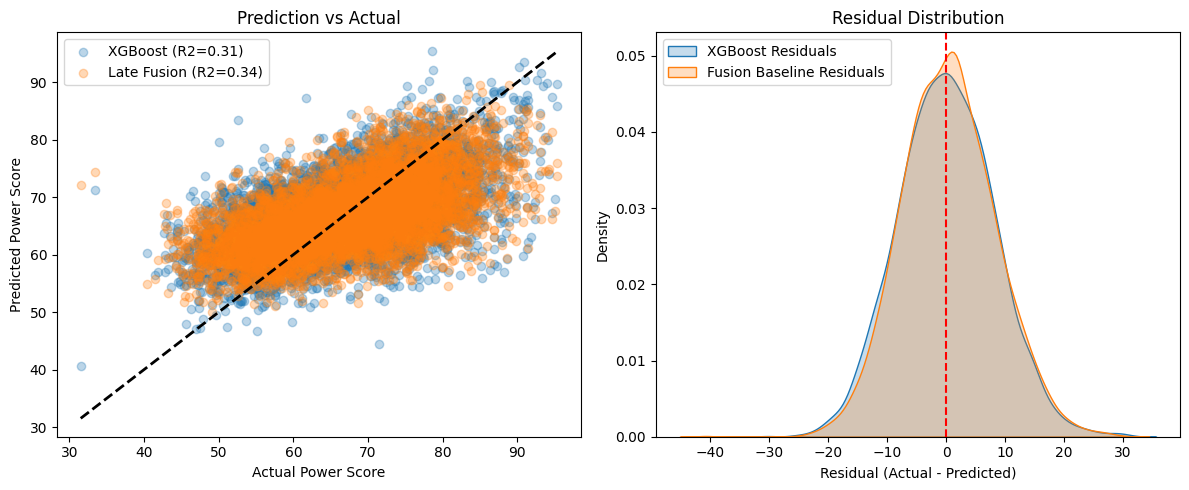

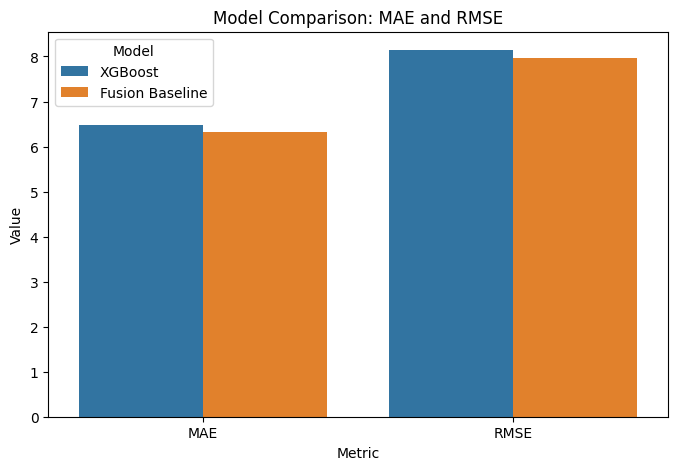

In [22]:
xgb_r2 = models_metrics["Full XGBoost"]["R2"]
xgb_mae = models_metrics["Full XGBoost"]["MAE"]
xgb_rmse = models_metrics["Full XGBoost"]["RMSE"]
fusion_r2 = models_metrics["Late Fusion"]["R2"]
fusion_mae = models_metrics["Late Fusion"]["MAE"]
fusion_rmse = models_metrics["Late Fusion"]["RMSE"]


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_xgb, alpha=0.3, label=f'XGBoost (R2={xgb_r2:.2f})', color='tab:blue')
plt.scatter(y_test, y_pred_fusion, alpha=0.3, label=f'Late Fusion (R2={fusion_r2:.2f})', color='tab:orange')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel('Actual Power Score')
plt.ylabel('Predicted Power Score')
plt.title('Prediction vs Actual')
plt.legend()

# 2. Plot Error Distribution
plt.subplot(1, 2, 2)
sns.kdeplot(y_test - y_pred_xgb, label='XGBoost Residuals', fill=True, color='tab:blue')
sns.kdeplot(y_test - y_pred_fusion, label='Fusion Baseline Residuals', fill=True, color='tab:orange')
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel('Residual (Actual - Predicted)')
plt.title('Residual Distribution')
plt.legend()

plt.tight_layout()
plt.show()

# 3. Metrics Comparison Bar Chart
metrics_df = pd.DataFrame({
    'Model': ['XGBoost', 'Fusion Baseline', 'XGBoost', 'Fusion Baseline'],
    'Metric': ['MAE', 'MAE', 'RMSE', 'RMSE'],
    'Value': [xgb_mae, fusion_mae, xgb_rmse, fusion_rmse]
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Metric', y='Value', hue='Model', data=metrics_df)
plt.title('Model Comparison: MAE and RMSE')
plt.show()